# text classification with knowledge distillation

exploring how knowledge distillation works for sentiment analysis. going to build a big teacher model and see if a tiny student can learn from it.

goals:
- load the imdb movie review dataset
- build teacher (big bidirectional lstm) 
- build student (small simple lstm)
- train both and compare them
- see if distillation actually helps

## imports and setup

In [1]:
# using keras instead of pytorch (had issues with torch on this machine)
# uncomment if you need to install
#!pip install tensorflow

import os
# hide tensorflow's c++ start up messages so the saved outputs only show the experiment
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import platform
import time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from scipy import stats

# python side tensorflow notices, such as the one about gpus on windows, would otherwise land in the outputs
tf.get_logger().setLevel('ERROR')

print(f"tensorflow version: {tf.__version__}")

tensorflow version: 2.21.0


### reproducibility

`SEED` fixes the validation split and the teacher, each student arm is trained once per entry of `SEEDS`

In [2]:
SEED = 0
SEEDS = [0, 1, 2]
# fixed seeds alone do not make tensorflow repeatable, deterministic kernels are needed as well
tf.config.experimental.enable_op_determinism()

In [3]:
print(f"python {platform.python_version()}, tensorflow {tf.__version__}, keras {keras.__version__}, "
      f"numpy {np.__version__}, pandas {pd.__version__}")
print(f"platform: {platform.platform()}, {os.cpu_count()} logical cpus, "
      f"gpus visible: {len(tf.config.list_physical_devices('GPU'))}")
print(f"data and teacher seed: {SEED}, student seeds: {SEEDS}")

python 3.12.15, tensorflow 2.21.0, keras 3.15.1, numpy 2.5.4, pandas 3.0.6
platform: Windows-10-10.0.19045-SP0, 16 logical cpus, gpus visible: 0
data and teacher seed: 0, student seeds: [0, 1, 2]


## loading real imdb movie review dataset

using the famous imdb dataset - 50k movie reviews labeled as positive or negative.

In [4]:
# imdb: 25k train and 25k test reviews, binary sentiment, already tokenized to word indices
from tensorflow.keras.datasets import imdb

# keep the 10k most frequent words, rarer ones become the out of vocabulary id 2
max_features = 10000
(x_train_raw, y_train), (x_test_raw, y_test) = imdb.load_data(num_words=max_features)

print(f"training samples: {len(x_train_raw)}")
print(f"test samples: {len(x_test_raw)}")
print(f"classes: {len(set(y_train))} (0=negative, 1=positive)")

training samples: 25000
test samples: 25000
classes: 2 (0=negative, 1=positive)


In [5]:
# both splits are balanced, so plain accuracy is a fair metric
train_dist = Counter(y_train)
test_dist = Counter(y_test)
print(f"\ntrain distribution: {dict(train_dist)}")
print(f"test distribution: {dict(test_dist)}")


train distribution: {np.int64(1): 12500, np.int64(0): 12500}
test distribution: {np.int64(0): 12500, np.int64(1): 12500}


In [6]:
# get the word index mapping to convert back to text
word_index = imdb.get_word_index()
reverse_word_index = {value: key for key, value in word_index.items()}

def decode_review(encoded_review):
    """convert sequence of integers back to text"""
    # load_data shifts word indices by 3: 0 is padding, 1 marks the start, 2 is out of vocabulary
    decoded = ' '.join([reverse_word_index.get(i - 3, '?') for i in encoded_review])
    return decoded

In [7]:
print("first positive review:")
pos_idx = list(y_train).index(1)
print(f"encoded: {x_train_raw[pos_idx][:20]}...")
print(f"decoded: {decode_review(x_train_raw[pos_idx])[:200]}...")
print(f"label: {y_train[pos_idx]} (positive)")

print("\nfirst negative review:")
neg_idx = list(y_train).index(0)  
print(f"encoded: {x_train_raw[neg_idx][:20]}...")
print(f"decoded: {decode_review(x_train_raw[neg_idx])[:200]}...")
print(f"label: {y_train[neg_idx]} (negative)")

first positive review:
encoded: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]...
decoded: ? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the sa...
label: 1 (positive)

first negative review:
encoded: [1, 194, 1153, 194, 8255, 78, 228, 5, 6, 1463, 4369, 5012, 134, 26, 4, 715, 8, 118, 1634, 14]...
decoded: ? big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst...
label: 0 (negative)


In [8]:
# pad sequences to same length for batching
from tensorflow.keras.preprocessing.sequence import pad_sequences

train_lengths = [len(seq) for seq in x_train_raw]
test_lengths = [len(seq) for seq in x_test_raw]

print(f"sequence length stats:")
print(f"train - min: {min(train_lengths)}, max: {max(train_lengths)}, avg: {np.mean(train_lengths):.1f}")
print(f"test - min: {min(test_lengths)}, max: {max(test_lengths)}, avg: {np.mean(test_lengths):.1f}")

sequence length stats:
train - min: 11, max: 2494, avg: 238.7
test - min: 7, max: 2315, avg: 230.8


In [9]:
# 256 tokens keep the bidirectional teacher trainable on a cpu, reviews longer than that lose their start
max_len = 256
print(f"\nusing max_len: {max_len}")

# zeros go before the review and long reviews keep their last 256 words, so the lstm's final
# state, the only one the classifier sees, comes right after real words instead of after padding
x_train = pad_sequences(x_train_raw, maxlen=max_len, padding='pre', truncating='pre')
x_test = pad_sequences(x_test_raw, maxlen=max_len, padding='pre', truncating='pre')


using max_len: 256


In [10]:
print(f"final shapes:")
print(f"x_train: {x_train.shape}")
print(f"x_test: {x_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test: {y_test.shape}")

# embedding table size: kept word ids run from 0 to max_features - 1
vocab_size = max_features
print(f"vocabulary size: {vocab_size}")

final shapes:
x_train: (25000, 256)
x_test: (25000, 256)
y_train: (25000,)
y_test: (25000,)
vocabulary size: 10000


## explore the real dataset

checking out the imdb reviews and their characteristics

In [11]:
print("positive review examples:")
pos_indices = [i for i, label in enumerate(y_train) if label == 1][:3]
for i, idx in enumerate(pos_indices):
    review = decode_review(x_train_raw[idx])
    print(f"\n{i+1}. {review[:300]}...")

print("\n" + "="*50)
print("negative review examples:")
neg_indices = [i for i, label in enumerate(y_train) if label == 0][:3]
for i, idx in enumerate(neg_indices):
    review = decode_review(x_train_raw[idx])
    print(f"\n{i+1}. {review[:300]}...")

positive review examples:

1. ? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there wa...

2. ? the ? ? at storytelling the traditional sort many years after the event i can still see in my ? eye an elderly lady my friend's mother retelling the battle of ? she makes the characters come alive her passion is that of an eye witness one to the events on the ? heath a mile or so from where she li...

3. ? lavish production values and solid performances in this straightforward adaption of jane ? satirical classic about the marriage game within and between the classes in ? 18th century england northam and paltrow are a ? mixture as friends who must pass through ? and lies to discover that they love e...

negative review examples:

1. ? big hair big boob

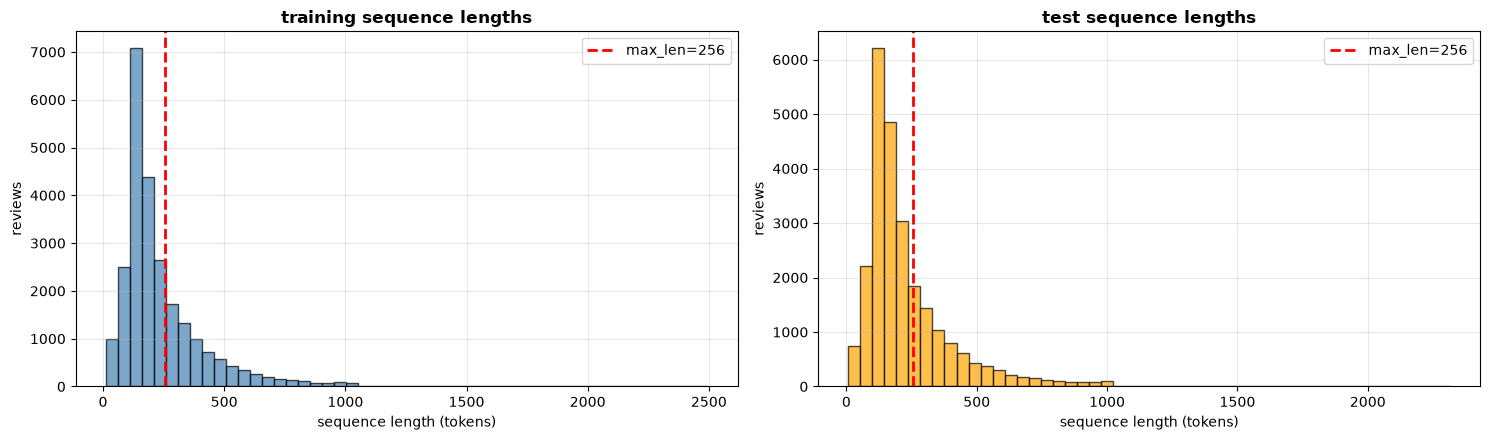

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, lengths, name, color in [(axes[0], train_lengths, 'training', 'steelblue'), (axes[1], test_lengths, 'test', 'orange')]:
    ax.hist(lengths, bins=50, edgecolor='black', alpha=0.7, color=color)
    ax.axvline(max_len, color='red', linestyle='--', linewidth=2, label=f'max_len={max_len}')
    ax.set_title(f'{name} sequence lengths', fontweight='bold')
    ax.set_xlabel('sequence length (tokens)')
    ax.set_ylabel('reviews')
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

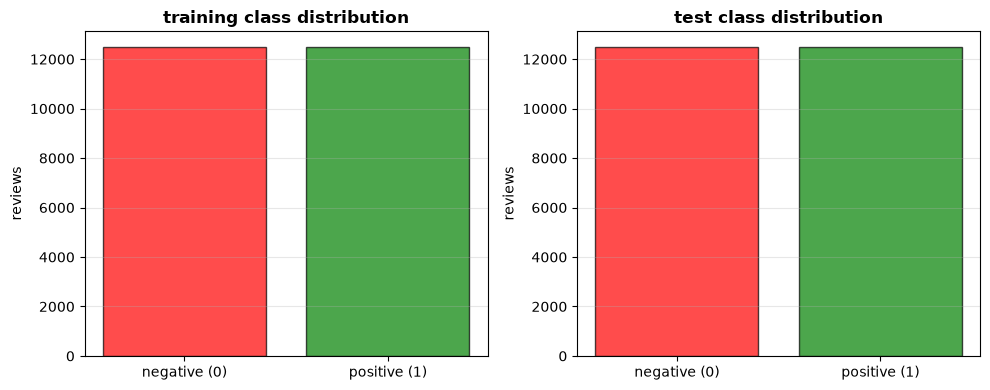

In [13]:
# index the counters by label so the bars cannot be swapped by insertion order
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, dist, name in [(axes[0], train_dist, 'training'), (axes[1], test_dist, 'test')]:
    ax.bar(['negative (0)', 'positive (1)'], [dist[0], dist[1]], color=['red', 'green'], alpha=0.7, edgecolor='black')
    ax.set_title(f'{name} class distribution', fontweight='bold')
    ax.set_ylabel('reviews')
    ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

In [14]:
print(f"coverage with max_len={max_len}:")
print(f"train: {sum(1 for l in train_lengths if l <= max_len)/len(train_lengths)*100:.1f}%")
print(f"test: {sum(1 for l in test_lengths if l <= max_len)/len(test_lengths)*100:.1f}%")

coverage with max_len=256:
train: 69.9%
test: 71.6%


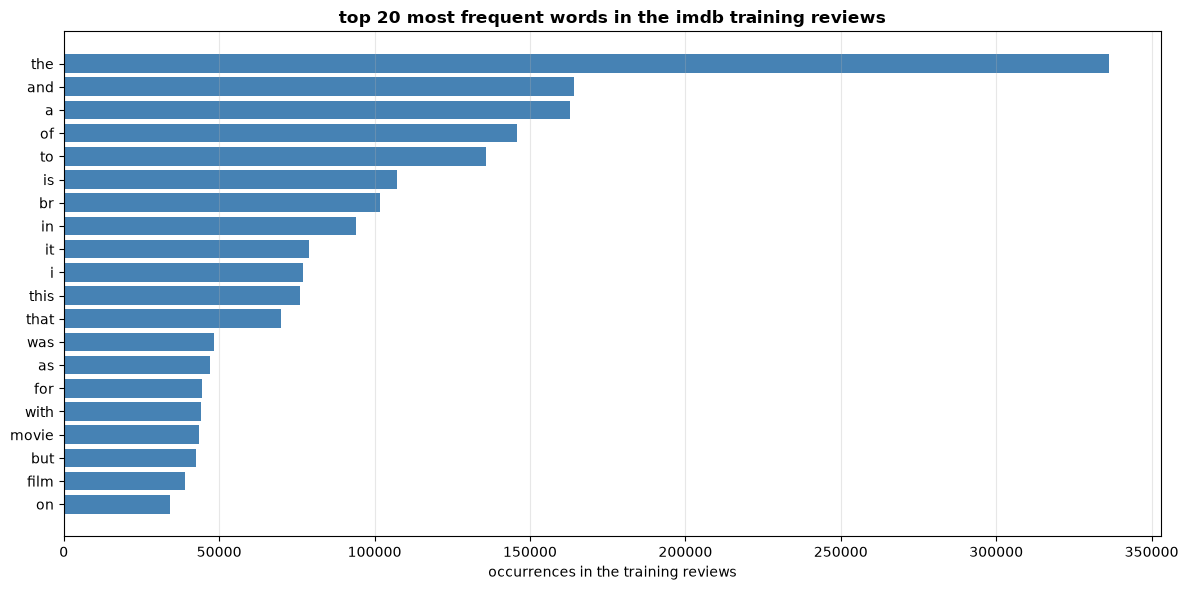

In [15]:
# real token counts over the training reviews, id 1 is the start marker and id 2 the out of vocabulary marker
token_counts = np.bincount(np.concatenate(x_train_raw), minlength=max_features)
top_ids = np.argsort(token_counts[3:])[::-1][:20] + 3
top_words = [reverse_word_index[i - 3] for i in top_ids]

plt.figure(figsize=(12, 6))
plt.barh(range(len(top_words)), token_counts[top_ids], color='steelblue')
plt.yticks(range(len(top_words)), top_words)
plt.xlabel('occurrences in the training reviews')
plt.title('top 20 most frequent words in the imdb training reviews', fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

In [16]:
# word ids start at 4, so ids below max_features keep max_features - 4 distinct words
word_tokens = token_counts[3:].sum() + token_counts[2]
print(f"total vocabulary size in imdb: {len(word_index):,} words")
print(f"kept: the {max_features - 4:,} most frequent words, ids 4 to {max_features - 1}")
print(f"training word tokens covered by the kept words: {token_counts[3:].sum() / word_tokens * 100:.1f}%")

total vocabulary size in imdb: 88,584 words
kept: the 9,996 most frequent words, ids 4 to 9999
training word tokens covered by the kept words: 94.3%


## data preprocessing complete

the imdb dataset comes pre-tokenized, so we just need to pad sequences for batching

In [17]:
# imdb arrives tokenized, so padding was the only preprocessing step
print("data ready for training:")
print(f"x_train shape: {x_train.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")
print(f"vocab size: {vocab_size}")
print(f"max sequence length: {max_len}")

example_idx = 0
print(f"\nexample padded sequence (last 20 tokens, the padding sits at the start):")
print(f"original length: {len(x_train_raw[example_idx])}")
print(f"padded sequence: {x_train[example_idx][-20:]}")
print(f"decoded: {decode_review(x_train[example_idx][-20:])}")

data ready for training:
x_train shape: (25000, 256)
x_test shape: (25000, 256)
y_train shape: (25000,)
y_test shape: (25000,)
vocab size: 10000
max sequence length: 256

example padded sequence (last 20 tokens, the padding sits at the start):
original length: 218
padded sequence: [  65   16   38 1334   88   12   16  283    5   16 4472  113  103   32
   15   16 5345   19  178   32]
decoded: story was so lovely because it was true and was someone's life after all that was shared with us all


hold out 5,000 training reviews as a validation set, everything looked at during training uses it so the test set is only read at the end

In [18]:
perm = np.random.default_rng(SEED).permutation(len(x_train))
val_idx, train_idx = perm[:5000], perm[5000:]
x_val, y_val = x_train[val_idx], y_train[val_idx]
x_train, y_train = x_train[train_idx], y_train[train_idx]
print(f"train: {len(x_train)}, validation: {len(x_val)}, test: {len(x_test)}")

train: 20000, validation: 5000, test: 25000


## build the teacher model

making a big bidirectional lstm with lots of parameters

In [19]:
def create_teacher_model(vocab_size, max_len):
    model = keras.Sequential([
        keras.layers.Input(shape=(max_len,)),
        keras.layers.Embedding(vocab_size, 128),
        keras.layers.Bidirectional(keras.layers.LSTM(256, return_sequences=True, dropout=0.3)),
        keras.layers.Bidirectional(keras.layers.LSTM(128, dropout=0.3)),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(64, activation='relu'),
        keras.layers.Dropout(0.3),
        # no softmax: the model emits logits so the distillation loss can soften them with softmax(z / t)
        keras.layers.Dense(2)
    ])
    return model

In [20]:
# teacher: two stacked bidirectional lstms, each review is read in both directions
create_teacher_model(vocab_size, max_len).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 256, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 256, 512)       │       788,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 256)            │       656,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,766,146 (10.55 MB)

 Trainable params: 2,766,146 (10.55 MB)

 Non-trainable params: 0 (0.00 B)

## build the student model

way smaller - just one lstm layer and fewer params

In [21]:
def create_student_model(vocab_size, max_len):
    model = keras.Sequential([
        keras.layers.Input(shape=(max_len,)),
        keras.layers.Embedding(vocab_size, 64),
        keras.layers.LSTM(64, dropout=0.3),
        keras.layers.Dense(32, activation='relu'),
        keras.layers.Dropout(0.3),
        # no softmax, as in the teacher
        keras.layers.Dense(2)
    ])
    return model

In [22]:
# student: one unidirectional lstm and a smaller embedding
create_student_model(vocab_size, max_len).summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 256, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,170 (2.58 MB)

 Trainable params: 675,170 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

## compare model sizes

checking how much smaller the student is

In [23]:
teacher_params = create_teacher_model(vocab_size, max_len).count_params()
student_params = create_student_model(vocab_size, max_len).count_params()

print("model size comparison:")
print(f"teacher: {teacher_params:,} parameters")
print(f"student: {student_params:,} parameters")
print(f"compression ratio: {teacher_params/student_params:.1f}x")
print(f"size reduction: {(1-student_params/teacher_params)*100:.1f}%")

model size comparison:
teacher: 2,766,146 parameters
student: 675,170 parameters
compression ratio: 4.1x
size reduction: 75.6%


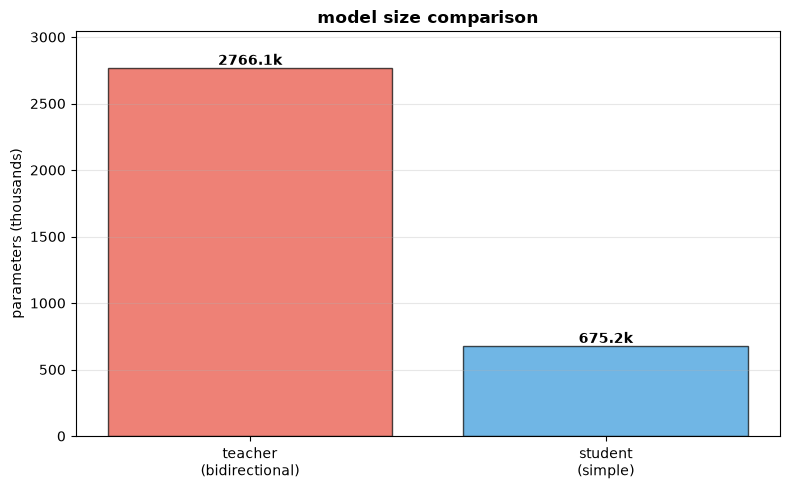

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
models = ['teacher\n(bidirectional)', 'student\n(simple)']
params = [teacher_params/1000, student_params/1000]  # in thousands
colors = ['#e74c3c', '#3498db']

bars = ax.bar(models, params, color=colors, alpha=0.7, edgecolor='black')
ax.set_ylabel('parameters (thousands)')
# headroom so the value labels above the bars stay inside the axes
ax.set_ylim(0, max(params) * 1.1)
ax.set_title('model size comparison', fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

for bar, param in zip(bars, params):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'{param:.1f}k',
            ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## implement knowledge distillation

the loss is `alpha * soft + (1 - alpha) * hard`: the soft term is `KL(softmax(teacher / T) || softmax(student / T))` times `T^2`, the hard term is the ordinary cross entropy with the labels.
with `alpha = 0` it is plain supervised training, which is how the teacher and the control student are trained.

In [25]:
def distillation_loss(y_true, student_logits, teacher_logits, temperature=4.0, alpha=0.7):
    """
    hinton style distillation loss: alpha * soft + (1 - alpha) * hard
    alpha is the weight on matching the teacher, 1 - alpha the weight on the true labels
    """
    # hard term at t=1: cross entropy with the true labels
    hard_loss = tf.reduce_mean(tf.nn.sparse_softmax_cross_entropy_with_logits(
        labels=tf.cast(y_true, tf.int32), logits=student_logits))
    if alpha == 0:
        return hard_loss

    # soft term: kl(teacher_t || student_t) on logits, a temperature above 1 flattens the teacher's
    # distribution so the probability it gives the wrong class carries signal, log space avoids an epsilon
    teacher_log = tf.nn.log_softmax(teacher_logits / temperature)
    student_log = tf.nn.log_softmax(student_logits / temperature)
    soft_loss = tf.reduce_sum(tf.exp(teacher_log) * (teacher_log - student_log), axis=1)
    # times t^2 to undo the 1 / t^2 shrink of the soft target gradients
    soft_loss = tf.reduce_mean(soft_loss) * (temperature ** 2)

    return alpha * soft_loss + (1 - alpha) * hard_loss

one compiled training step, a custom step because `fit()` has no hook for feeding the teacher's outputs into the loss

In [26]:
def make_train_step(model, optimizer, temperature, alpha):
    @tf.function(reduce_retracing=True)
    def train_step(x, y, teacher_logits):
        with tf.GradientTape() as tape:
            logits = model(x, training=True)
            loss = distillation_loss(y, logits, teacher_logits, temperature, alpha)
        # only this model's variables get gradients, which is what keeps the teacher frozen
        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        return loss
    return train_step

In [27]:
def accuracy(model, x, y):
    # inference mode turns dropout off, argmax of the logits is the same at every temperature
    logits = model.predict(x, batch_size=500, verbose=0)
    return float(np.mean(np.argmax(logits, axis=1) == y))

the same loop trains the teacher, the control student and the distilled student.
for a given seed the two students start from the same weights and see the same shuffled batches, so the loss is the only difference between them

In [28]:
def train(model, x, y, teacher_logits=None, temperature=1.0, alpha=0.0, epochs=5,
          batch_size=64, seed=0, keep_best=False):
    optimizer = keras.optimizers.Adam(learning_rate=0.001)
    train_step = make_train_step(model, optimizer, temperature, alpha)
    # one generator per run, so the batch order depends on the seed and nothing else
    rng = np.random.default_rng(seed)
    history = {'epoch': [], 'val_acc': []}
    best_acc, best_weights = -1.0, None
    for epoch in range(1, epochs + 1):
        start_time = time.time()
        order = rng.permutation(len(x))
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            batch_teacher = None if teacher_logits is None else teacher_logits[idx]
            train_step(x[idx], y[idx], batch_teacher)
        history['epoch'].append(epoch)
        history['val_acc'].append(accuracy(model, x_val, y_val))
        print(f"  epoch {epoch}/{epochs}: validation accuracy {history['val_acc'][-1]:.4f}, {time.time() - start_time:.0f} s")
        if keep_best and history['val_acc'][-1] > best_acc:
            best_acc, best_weights = history['val_acc'][-1], model.get_weights()
    # keep_best picks the epoch on the validation set, so the test set plays no part in it
    if keep_best:
        model.set_weights(best_weights)
    return history

In [29]:
def new_model(create, seed):
    # the global seed fixes the initial weights and the dropout masks of the model built next
    keras.utils.set_random_seed(seed)
    return create(vocab_size, max_len)

In [30]:
def train_student(arm, seed):
    # the control gets no teacher and alpha=0, everything else is identical to the distilled run
    model = new_model(create_student_model, seed)
    if arm == 'control':
        history = train(model, x_train, y_train, epochs=epochs, seed=seed)
    else:
        history = train(model, x_train, y_train, teacher_logits=teacher_train_logits,
                        temperature=temperature, alpha=alpha, epochs=epochs, seed=seed)
    return model, history

## train the teacher

training the big model first so we can use it to teach the student, for up to 10 epochs, keeping the weights from the epoch with the best validation accuracy

In [31]:
# the teacher was still improving after 3 epochs, a teacher weaker than the student has nothing to teach it
teacher_epochs = 10

In [32]:
# the teacher is trained first, on hard labels only
t0 = time.time()
teacher = new_model(create_teacher_model, SEED)
teacher_history = train(teacher, x_train, y_train, epochs=teacher_epochs, seed=SEED, keep_best=True)
print(f"teacher trained in {(time.time() - t0) / 60:.1f} min")
best_epoch = int(np.argmax(teacher_history['val_acc'])) + 1
print(f"kept the weights from epoch {best_epoch}, validation accuracy {max(teacher_history['val_acc']):.4f}")

  epoch 1/10: validation accuracy 0.5372, 351 s


  epoch 2/10: validation accuracy 0.7640, 354 s


  epoch 3/10: validation accuracy 0.8150, 372 s


  epoch 4/10: validation accuracy 0.8358, 383 s


  epoch 5/10: validation accuracy 0.8772, 393 s


  epoch 6/10: validation accuracy 0.8820, 401 s


  epoch 7/10: validation accuracy 0.8750, 399 s


  epoch 8/10: validation accuracy 0.8692, 406 s


  epoch 9/10: validation accuracy 0.8550, 411 s


  epoch 10/10: validation accuracy 0.8772, 408 s
teacher trained in 64.6 min
kept the weights from epoch 6, validation accuracy 0.8820


freeze the teacher and compute its logits for every training review once, with no augmentation these are exactly the logits it would give batch by batch

In [33]:
teacher.trainable = False
teacher_train_logits = teacher.predict(x_train, batch_size=500, verbose=0)
print(f"teacher logits: {teacher_train_logits.shape}")

teacher logits: (20000, 2)


## train the students

the distilled student and the control student get the same training set, epochs, batch size and seed, and each pair is trained once per seed.
`T = 4` and `alpha = 0.7` were fixed before any results were seen and are not tuned here

In [34]:
# t=4 gives moderately soft targets, alpha=0.7 puts most of the weight on the teacher
temperature = 4.0
alpha = 0.7
epochs = 5

In [35]:
runs = {'control': [], 'distilled': []}
t0 = time.time()
for seed in SEEDS:
    for arm in runs:
        print(f"seed {seed}, {arm}")
        model, history = train_student(arm, seed)
        runs[arm].append({'seed': seed, 'model': model, 'history': history})
print(f"{len(SEEDS) * 2} student runs in {(time.time() - t0) / 60:.1f} min")

seed 0, control


  epoch 1/5: validation accuracy 0.8668, 18 s


  epoch 2/5: validation accuracy 0.8584, 16 s


  epoch 3/5: validation accuracy 0.8544, 17 s


  epoch 4/5: validation accuracy 0.8742, 20 s


...

  epoch 1/5: validation accuracy 0.8538, 28 s


  epoch 2/5: validation accuracy 0.8846, 24 s


  epoch 3/5: validation accuracy 0.8778, 24 s


  epoch 4/5: validation accuracy 0.8756, 25 s


  epoch 5/5: validation accuracy 0.8836, 25 s
6 student runs in 11.1 min


In [36]:
# the seed 0 pair is used for the qualitative checks further down
student_baseline = runs['control'][0]['model']
student_distilled = runs['distilled'][0]['model']

## compare all models

validation accuracy after every epoch, mean and standard deviation over the seeds, then the test set, read once at the end

In [37]:
RESULTS_DIR = os.path.join('..', 'results', 'text_classification')

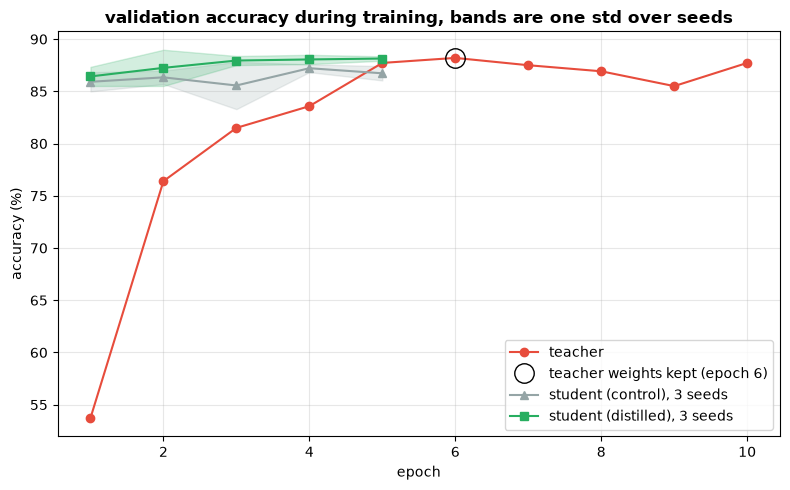

In [38]:
fig, ax = plt.subplots(figsize=(8, 5))
teacher_curve = np.array(teacher_history['val_acc']) * 100
ax.plot(teacher_history['epoch'], teacher_curve, marker='o', color='#e74c3c', label='teacher')
# the teacher keeps its best validation epoch, ring it so the curve is not read as the final weights
ax.plot(best_epoch, teacher_curve[best_epoch - 1], marker='o', markersize=14, markerfacecolor='none',
        markeredgecolor='black', linestyle='none', label=f'teacher weights kept (epoch {best_epoch})')
for arm, color, marker in [('control', '#95a5a6', '^'), ('distilled', '#27ae60', 's')]:
    curves = np.array([run['history']['val_acc'] for run in runs[arm]]) * 100
    mean, std = curves.mean(axis=0), curves.std(axis=0, ddof=1)
    epochs_seen = runs[arm][0]['history']['epoch']
    ax.plot(epochs_seen, mean, marker=marker, color=color, label=f'student ({arm}), {len(curves)} seeds')
    ax.fill_between(epochs_seen, mean - std, mean + std, color=color, alpha=0.2)
ax.set_title('validation accuracy during training, bands are one std over seeds', fontweight='bold')
ax.set_xlabel('epoch')
ax.set_ylabel('accuracy (%)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'text_distillation_results.png'), dpi=150, bbox_inches='tight')
plt.show()

In [39]:
teacher_acc = accuracy(teacher, x_test, y_test) * 100
for arm in runs:
    for run in runs[arm]:
        run['test_acc'] = accuracy(run['model'], x_test, y_test) * 100

In [40]:
per_seed = pd.DataFrame({arm: [run['test_acc'] for run in runs[arm]] for arm in runs},
                        index=pd.Index(SEEDS, name='seed'))
per_seed['distilled - control'] = per_seed['distilled'] - per_seed['control']
print("test accuracy (%) per seed")
print(per_seed.round(2).to_string())

test accuracy (%) per seed
      control  distilled  distilled - control
seed                                         
0       85.74      87.49                 1.74
1       86.38      87.60                 1.22
2       85.40      87.54                 2.14


### results table

In [41]:
def result_row(name, params, accs):
    accs = np.atleast_1d(accs)
    return {'model': name, 'parameters': params, 'size (MB)': round(params * 4 / 1e6, 2),
            'runs': len(accs), 'test acc mean (%)': round(float(np.mean(accs)), 2),
            'test acc std': round(float(np.std(accs, ddof=1)), 2) if len(accs) > 1 else float('nan')}

results = pd.DataFrame([
    result_row('teacher', teacher_params, teacher_acc),
    result_row('student, control', student_params, per_seed['control']),
    result_row(f'student, distilled (t={temperature}, alpha={alpha})', student_params, per_seed['distilled']),
])
print(results.to_string(index=False))

                                model  parameters  size (MB)  runs  test acc mean (%)  test acc std
                              teacher     2766146      11.06     1              87.48           NaN
                     student, control      675170       2.70     3              85.84          0.50
student, distilled (t=4.0, alpha=0.7)      675170       2.70     3              87.54          0.05


the two students share each seed, so the differences are paired, a paired t test says whether the mean difference stands out from seed noise

In [42]:
diff = per_seed['distilled - control']
test = stats.ttest_rel(per_seed['distilled'], per_seed['control'])
print(f"distilled minus control: {diff.mean():+.2f} +/- {diff.std(ddof=1):.2f} percentage points "
      f"(mean +/- std over {len(diff)} seeds), distilled ahead on {(diff > 0).sum()} of {len(diff)} seeds, "
      f"paired t test p = {test.pvalue:.3f}")

distilled minus control: +1.70 +/- 0.47 percentage points (mean +/- std over 3 seeds), distilled ahead on 3 of 3 seeds, paired t test p = 0.024


## test on some examples

trying the models on actual text to see how they predict

In [43]:
# hand written reviews, a quick qualitative check outside the imdb test set
test_examples_raw = [
    "this movie was absolutely fantastic with amazing acting and plot",
    "worst film ever terrible acting boring story waste of time",
    "pretty good movie enjoyed most parts but ending was weak", 
    "not the best but had some decent moments worth watching",
    "horrible cinematography poor dialogue would not recommend",
    "brilliant masterpiece excellent direction superb performances"
]

print("converting test examples to sequences...")

converting test examples to sequences...


In [44]:
def text_to_sequence(text, word_index, max_features, index_from=3):
    """map words to the same ids imdb.load_data produces"""
    # load_data starts every review with id 1, shifts word ranks by index_from and
    # replaces ids outside the kept vocabulary with the out of vocabulary id 2
    sequence = [1]
    for word in text.lower().split():
        rank = word_index.get(word)
        if rank is None or rank + index_from >= max_features:
            sequence.append(2)
        else:
            sequence.append(rank + index_from)
    return sequence

In [45]:
test_sequences = [text_to_sequence(text, word_index, max_features) for text in test_examples_raw]
test_padded = pad_sequences(test_sequences, maxlen=max_len, padding='pre')

In [46]:
print("test sequences created:")
for i, (text, seq) in enumerate(zip(test_examples_raw, test_sequences)):
    print(f"{i+1}. '{text}' -> {len(seq) - 1} words, {seq.count(2)} out of vocabulary")

test sequences created:
1. 'this movie was absolutely fantastic with amazing acting and plot' -> 10 words, 0 out of vocabulary
2. 'worst film ever terrible acting boring story waste of time' -> 10 words, 0 out of vocabulary
3. 'pretty good movie enjoyed most parts but ending was weak' -> 10 words, 0 out of vocabulary
4. 'not the best but had some decent moments worth watching' -> 10 words, 0 out of vocabulary
5. 'horrible cinematography poor dialogue would not recommend' -> 7 words, 0 out of vocabulary
6. 'brilliant masterpiece excellent direction superb performances' -> 6 words, 0 out of vocabulary


In [47]:
teacher_preds = tf.nn.softmax(teacher.predict(test_padded, verbose=0)).numpy()
baseline_preds = tf.nn.softmax(student_baseline.predict(test_padded, verbose=0)).numpy()
distilled_preds = tf.nn.softmax(student_distilled.predict(test_padded, verbose=0)).numpy()

In [48]:
print("\npredictions on movie reviews:")
print("="*80)
for i, text in enumerate(test_examples_raw):
    print(f"\nreview: '{text}'")
    print(f"  teacher: {'positive' if np.argmax(teacher_preds[i]) == 1 else 'negative'} (conf: {np.max(teacher_preds[i]):.3f})")
    print(f"  control: {'positive' if np.argmax(baseline_preds[i]) == 1 else 'negative'} (conf: {np.max(baseline_preds[i]):.3f})")
    print(f"  distilled: {'positive' if np.argmax(distilled_preds[i]) == 1 else 'negative'} (conf: {np.max(distilled_preds[i]):.3f})")


predictions on movie reviews:

review: 'this movie was absolutely fantastic with amazing acting and plot'
  teacher: positive (conf: 0.973)
  control: positive (conf: 0.760)
  distilled: positive (conf: 0.848)

review: 'worst film ever terrible acting boring story waste of time'
  teacher: negative (conf: 0.996)
  control: negative (conf: 0.999)
  distilled: negative (conf: 0.986)

review: 'pretty good movie enjoyed most parts but ending was weak'
  teacher: positive (conf: 0.759)
  control: negative (conf: 0.782)
  distilled: positive (conf: 0.592)

review: 'not the best but had some decent moments worth watching'
  teacher: negative (conf: 0.742)
  control: negative (conf: 0.532)
  distilled: positive (conf: 0.530)

review: 'horrible cinematography poor dialogue would not recommend'
  teacher: negative (conf: 0.996)
  control: negative (conf: 0.993)
  distilled: negative (conf: 0.923)

review: 'brilliant masterpiece excellent direction superb performances'
  teacher: positive (conf:

## analyze prediction confidence

checking how confident each model is in its predictions

In [49]:
# confidence is the probability of the predicted class
teacher_test_preds = tf.nn.softmax(teacher.predict(x_test, verbose=0)).numpy()
baseline_test_preds = tf.nn.softmax(student_baseline.predict(x_test, verbose=0)).numpy()
distilled_test_preds = tf.nn.softmax(student_distilled.predict(x_test, verbose=0)).numpy()

teacher_conf = np.max(teacher_test_preds, axis=1)
baseline_conf = np.max(baseline_test_preds, axis=1)
distilled_conf = np.max(distilled_test_preds, axis=1)

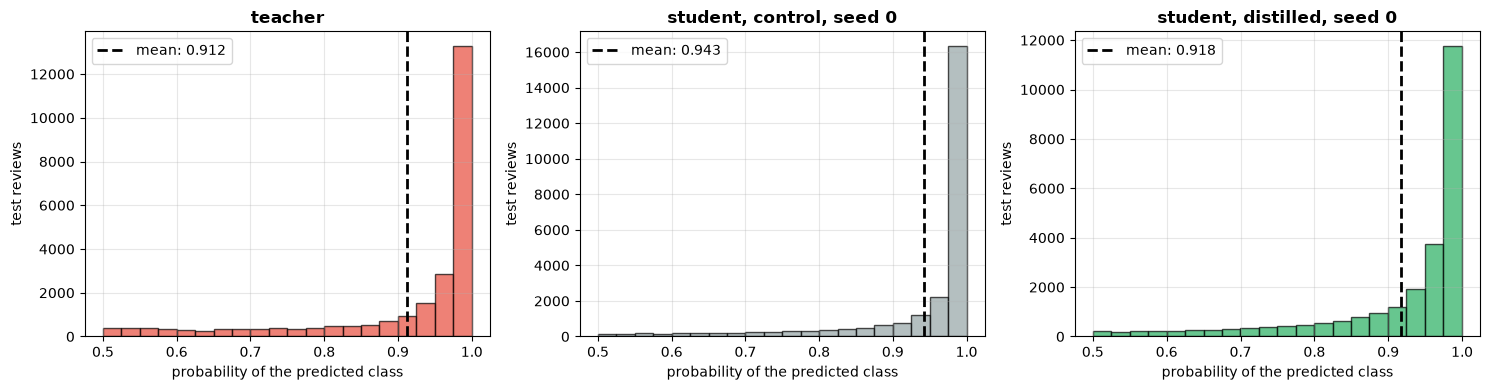

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, conf, title, color in [(axes[0], teacher_conf, 'teacher', '#e74c3c'),
                               (axes[1], baseline_conf, 'student, control, seed 0', '#95a5a6'),
                               (axes[2], distilled_conf, 'student, distilled, seed 0', '#27ae60')]:
    ax.hist(conf, bins=20, color=color, alpha=0.7, edgecolor='black')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('probability of the predicted class')
    ax.set_ylabel('test reviews')
    ax.axvline(np.mean(conf), color='black', linestyle='--', linewidth=2, label=f'mean: {np.mean(conf):.3f}')
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [51]:
print("average confidence scores:")
print(f"teacher: {np.mean(teacher_conf):.3f}")
print(f"control: {np.mean(baseline_conf):.3f}")
print(f"distilled: {np.mean(distilled_conf):.3f}")

average confidence scores:
teacher: 0.912
control: 0.943
distilled: 0.918


## final results

In [52]:
print(f"compression: {teacher_params/student_params:.1f}x fewer parameters "
      f"({teacher_params:,} against {student_params:,})")
print(results.to_string(index=False))

compression: 4.1x fewer parameters (2,766,146 against 675,170)
                                model  parameters  size (MB)  runs  test acc mean (%)  test acc std
                              teacher     2766146      11.06     1              87.48           NaN
                     student, control      675170       2.70     3              85.84          0.50
student, distilled (t=4.0, alpha=0.7)      675170       2.70     3              87.54          0.05
